# Kunci Lab 5: Deret Waktu dan Data Panel



## Persiapan: alamat data

Jalankan sel alamat data dan instalasi `linearmodels` dengan koneksi internet.



**Alur sesi:** kita menggunakan urutan waktu dan pengamatan berulang. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan data aktual, ramalan, dan pola antarunit.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
%pip install "linearmodels==7.1" -q


Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import statsmodels.api as sm



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


## Latihan 1: ADF dan ARIMA untuk saham



<!-- kamus_variabel:ts_saham.csv -->

### Kenali data: Harga saham simulasi

**Data:** `data/ts_saham.csv`. **Satu baris:** satu urutan periode simulasi; bukan tanggal kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `obs` | Urutan waktu pengamatan. | 1, 2, 3, ...; frekuensi kalender tidak dirinci | Penanda waktu |
| `saham` | Deret harga saham simulasi untuk uji stasioneritas dan peramalan. | Level harga; skala uang tidak dirinci | Deret yang dianalisis |

Nomor obs tidak menunjukkan tanggal/bulan/tahun tertentu. Angka level dan perubahan persennya harus dibedakan.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [4]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

saham_ts = pd.read_csv(URL_DATA + "ts_saham.csv")

saham_ts.head()

,obs,saham
0,1,5000
1,2,5050
2,3,5025
3,4,5100
4,5,5080


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [5]:
print("ADF level       :", round(adfuller(saham_ts["saham"])[1], 4))
print("ADF selisih     :", round(adfuller(saham_ts["saham"].diff().dropna())[1], 4))

model_saham = ARIMA(saham_ts["saham"], order=(1, 1, 0)).fit()
ramalan = model_saham.get_forecast(steps=5).predicted_mean
print("Ramalan 5 periode:", np.round(np.asarray(ramalan), 1).tolist())

ADF level       : 0.9763
ADF selisih     : 0.0
Ramalan 5 periode: [5787.6, 5787.4, 5787.4, 5787.4, 5787.4]


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_19112\2792152063.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF level       :", round(adfuller(saham_ts["saham"])[1], 4))
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_19112\2792152063.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF selisih     :", round(adfuller(saham_ts["saham"].diff().dropna

### Lihat rentang data yang dipakai meramal

Garis putus-putus dimulai setelah pengamatan terakhir. Bagian ramalan tidak diperlakukan sebagai data aktual.

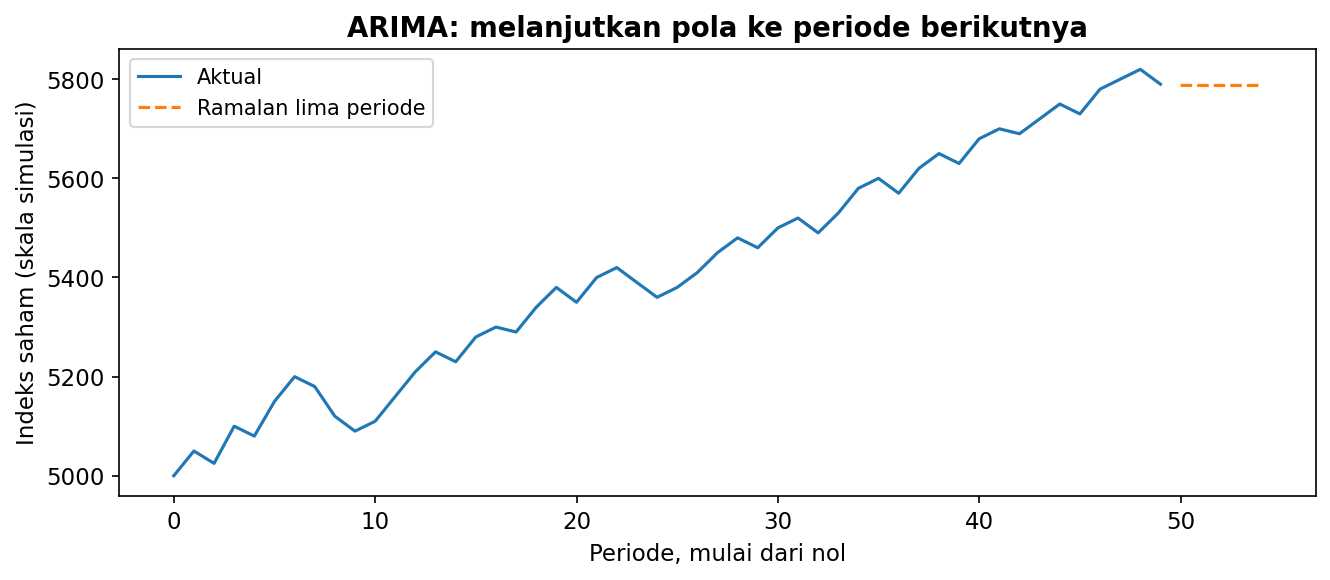

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(saham_ts.index, saham_ts["saham"], label="Aktual")
ax.plot(ramalan.index, ramalan, "--", label="Ramalan lima periode")
ax.set_xlabel("Periode, mulai dari nol")
ax.set_ylabel("Indeks saham (skala simulasi)")
ax.set_title("ARIMA: melanjutkan pola ke periode berikutnya")
ax.legend()
plt.tight_layout()
plt.show()

**Cara membaca:** Ini ramalan titik dari contoh ARIMA, bukan jaminan harga yang akan terjadi. Cocokkan perubahan level dengan hasil uji stasioneritas yang dicetak sebelumnya.

Kesimpulan: saham tidak stasioner di level (p = 0,98) dan stasioner
setelah selisih (p = 0,0000), khas random walk. Ramalan ARIMA(1,1,0)
hampir datar di sekitar 5.787: wajar, karena random walk tidak bisa
diprediksi arahnya.



## Latihan 2: kointegrasi IHSG dan emas



<!-- kamus_variabel:ihsg_emas.csv -->

### Kenali data: IHSG dan harga emas simulasi

**Data:** `data/ihsg_emas.csv`. **Satu baris:** satu bulan berurutan pada contoh simulasi.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Bulan` | Urutan bulan pengamatan. | Nomor bulan; tanggal kalender tidak dicantumkan | Penanda waktu |
| `IHSG_Y` | Indeks Harga Saham Gabungan dalam contoh simulasi. | Poin indeks | Y: target |
| `Emas_X` | Harga emas pada contoh simulasi. | Mata uang dan berat acuan tidak dirinci | X: penjelas |

Tabel ini adalah contoh simulasi; berbeda dari data IHSG harian unduhan Yahoo Finance.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [7]:
from statsmodels.tsa.stattools import coint

ie = pd.read_csv(URL_DATA + "ihsg_emas.csv")

ie.head()

,Bulan,IHSG_Y,Emas_X
0,1,4500.10,1500.5
1,2,4520.25,1510.2
2,3,4480.15,1525.4
3,4,4495.30,1515.8
4,5,4550.60,1490.2


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [8]:
p_kointe = coint(ie["IHSG_Y"], ie["Emas_X"])[1]
print("Uji kointegrasi: p =", round(p_kointe, 4))

Uji kointegrasi: p = 0.4941


### Dua seri yang bergerak bersama belum tentu berkointegrasi

Kedua seri menggunakan skala berbeda, sehingga ditampilkan terpisah dengan sumbu waktu bersama.

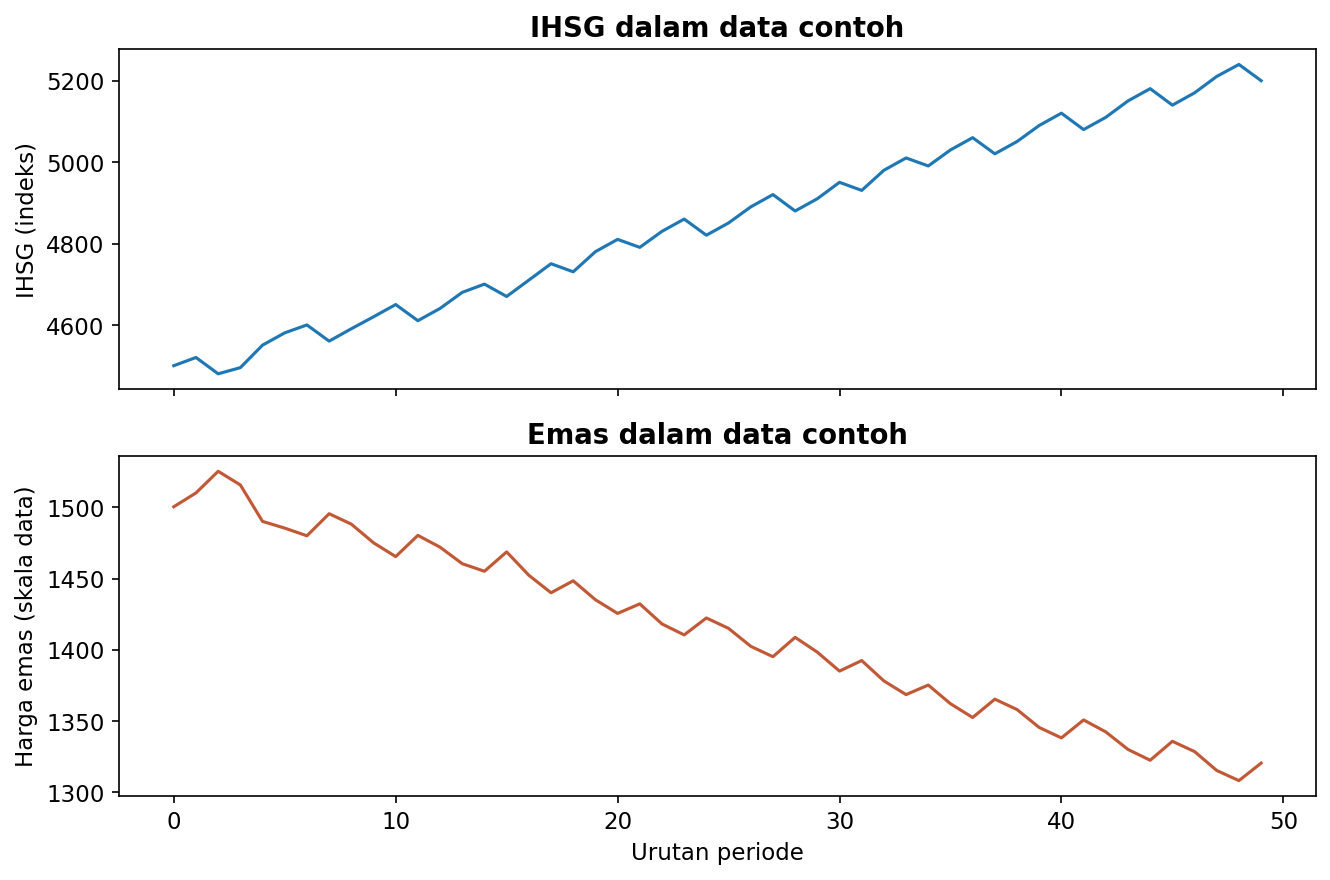

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(ie["IHSG_Y"])
axes[0].set(ylabel="IHSG (indeks)", title="IHSG dalam data contoh")
axes[1].plot(ie["Emas_X"], color="#C15937")
axes[1].set(xlabel="Urutan periode", ylabel="Harga emas (skala data)", title="Emas dalam data contoh")
plt.tight_layout()
plt.show()

**Cara membaca:** Kemiripan arah garis membantu mengajukan pertanyaan. Keputusan kointegrasi tetap mengikuti pemeriksaan orde integrasi dan uji Engle–Granger.

Kesimpulan: p = 0,4941, jauh di atas 0,05. IHSG dan emas TIDAK
terkointegrasi. Walaupun dua-duanya bergerak sepanjang waktu, tidak ada
hubungan jangka panjang yang mengikat. Karena itu ECM tidak layak
dipakai di kasus ini. Bandingkan dengan konsumsi-pendapatan
(p coint = 0,0001). Pada konsumsi-pendapatan, ADF log di level justru
menolak akar unit; karena itu ECM di sana hanya demonstrasi perhitungan,
bukan bukti empiris kointegrasi yang memenuhi syarat I(1).



## Latihan 3: panel retail CEM vs FEM



<!-- kamus_variabel:panel_retail.csv -->

### Kenali data: Panel toko ritel

**Data:** `data/panel_retail.csv`. **Satu baris:** satu cabang toko pada satu bulan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `StoreID` | Kode cabang toko. | Nomor identitas toko | Penanda, bukan besaran ekonomi |
| `Month` | Urutan bulan dalam panel. | Bulan ke-1, ke-2, ... | Penanda waktu |
| `Sales_Y` | Besarnya penjualan toko pada bulan tersebut. | Satuan/skala tidak dirinci sumber | Y: target |
| `Ads_X1` | Biaya iklan cabang toko. | Satuan/skala tidak dirinci sumber | X: penjelas |
| `Discount_X2` | Proporsi potongan harga. | Pecahan; 0,10 berarti diskon 10% | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [10]:
from linearmodels.panel import PanelOLS

retail = pd.read_csv(URL_DATA + "panel_retail.csv")

retail.head()

,StoreID,Month,Sales_Y,Ads_X1,Discount_X2
0,1,1,100.5,5.2,0.10
1,1,2,102.3,5.5,0.10
2,1,3,110.5,6.0,0.15
3,1,4,108.2,5.8,0.12
4,1,5,120.1,7.0,0.20


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [11]:
retail = retail.set_index(["StoreID", "Month"])
y = retail["Sales_Y"]
X = retail[["Ads_X1", "Discount_X2"]]

cem = PanelOLS(y, sm.add_constant(X)).fit()
fem = PanelOLS(y, X, entity_effects=True).fit()

print("CEM:")
print(cem.params.round(3))
print("\nFEM:")
print(fem.params.round(3))

CEM:
const           22.430
Ads_X1          18.836
Discount_X2   -157.069
Name: parameter, dtype: float64

FEM:
Ads_X1         11.060
Discount_X2    -1.939
Name: parameter, dtype: float64


### Bandingkan penjualan beberapa toko dari waktu ke waktu

Satu toko dapat mempunyai tingkat penjualan yang konsisten berbeda dari toko lain.

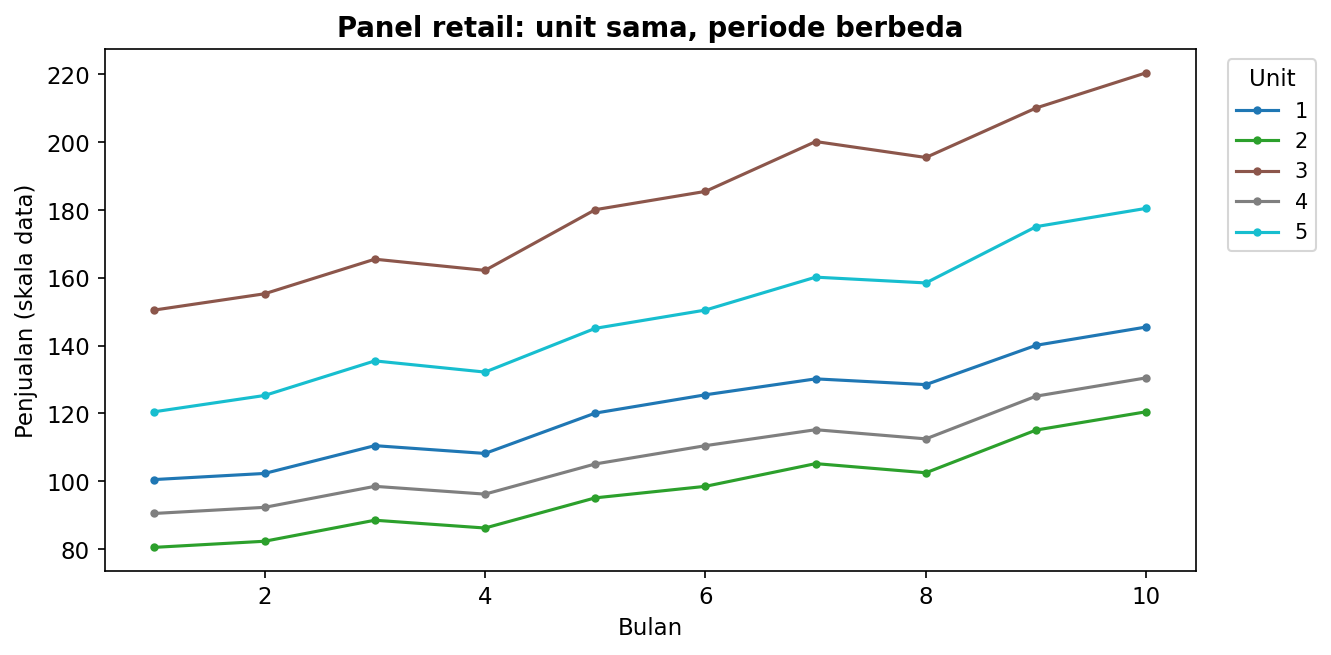

In [12]:
tabel_garis = retail.reset_index().pivot(index="Month", columns="StoreID", values="Sales_Y")
ax = tabel_garis.plot(colormap="tab10", figsize=(9, 4.5), marker="o", markersize=3)
ax.set_xlabel("Bulan")
ax.set_ylabel("Penjualan (skala data)")
ax.set_title("Panel retail: unit sama, periode berbeda")
ax.legend(title="Unit", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** Perbedaan tingkat antartoko menjadi salah satu alasan mempertimbangkan efek individu. Setelah membaca grafik, bandingkan koefisien CEM dan FEM pada tabel.

Kesimpulan: di CEM, koefisien diskon -157 (signifikan) karena model
mencampur perbedaan antar toko: toko beromzet tinggi kebetulan juga
memberi diskon besar. Setelah efek toko dikontrol (FEM), koefisien
diskon hanya -1,9 dan tidak signifikan. Untuk kebijakan diskon, yang
relevan adalah perubahan DI DALAM toko yang sama, jadi FEM lebih
dipercaya. Uji Chow p-value sangat kecil, mendukung FEM.
